In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all sheets and combine into one DataFrame
df_dict = pd.read_excel("../data/raw/online_retail_II.xlsx", sheet_name=None)
df = pd.concat(df_dict.values(), ignore_index=True)

# Basic shape
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 1067371, Columns: 8


In [2]:
# First 5 rows
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [4]:
# Missing values per column
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [5]:
# Descriptive statistics for numeric columns
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [6]:
# Check unique values in key columns
print("Unique invoices:", df['Invoice'].nunique())
print("Unique customers:", df['Customer ID'].nunique())
print("Unique countries:", df['Country'].nunique())

# Date range
print("Date range:", df['InvoiceDate'].min(), "to", df['InvoiceDate'].max())

Unique invoices: 53628
Unique customers: 5942
Unique countries: 43
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [7]:
# Negative quantities (returns)
print("Negative Quantity rows:", (df['Quantity'] < 0).sum())

# Zero or negative prices
print("Zero/Negative Price rows:", (df['Price'] <= 0).sum())

Negative Quantity rows: 22950
Zero/Negative Price rows: 6207


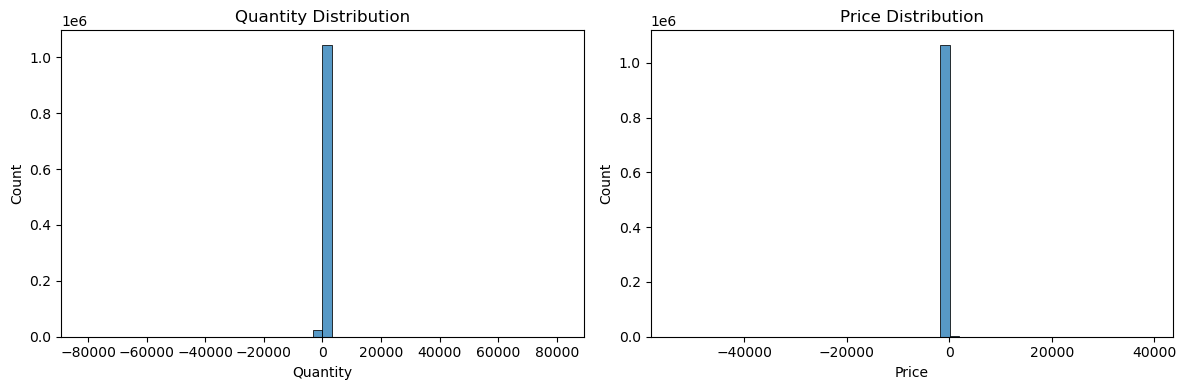

In [8]:
# Distribution of Quantity and Price
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Quantity'], bins=50, ax=axes[0])
axes[0].set_title('Quantity Distribution')
sns.histplot(df['Price'], bins=50, ax=axes[1])
axes[1].set_title('Price Distribution')
plt.tight_layout()
plt.show()